# Budget selection for weighted CGFS on validation data only

Response to Reviewer 1 (Rev. 2): the budget $k^\star$ must be chosen without looking
at the test partitions used for the final results.

**Protocol (per seed).**

1. **Outer split** — the *same* stratified 70/30 split as the benchmark notebook
   (`train_test_split(X, y, test_size=0.30, stratify=y, random_state=seed)`).
   The test partition is discarded immediately and never used here.
2. **Inner split** — the 70% training partition is split again, stratified, into a
   *fitting* subset (80%) and a *validation* subset (20%).
3. Screening, z-scoring, rectified-cosine similarity, MI weights and the CGFS greedy
   are fitted on the fitting subset only; a random forest is trained on the fitting
   subset at every budget and scored on the validation subset.
4. The validation curves are averaged over seeds and the tolerance rule (Eq. kstar,
   $\tau = 1\%$) picks $k^\star$.
5. **Sampled variant** — each 20% stratified sample is drawn from the *training
   partition* of the outer split (same absolute row count as in the paper), then
   goes through steps 2–4.

The test partitions are touched only afterwards, by the benchmark notebook, once,
at the selected $k^\star$.

**Before running:** `SEEDS` must equal the seeds of the benchmark notebook and the
outer split call must be identical to it; otherwise validation rows could fall in
the benchmark's test partitions and the leakage would come back.

Helper cells below are verbatim from the earlier `CGFS_sample_vs_full_experiment.ipynb`,
which this notebook supersedes (it remains available in the git history).

## 1. Configuration

In [1]:
# ---------------------------------------------------------------- config ----
DATA_DIR = "."                   # the DatasetSpec paths below are relative to this
OUT_DIR  = "."

DATASETS_TO_RUN = ["rt-iot", "edge-iiot", "cic-iot"]

# MUST be the seeds of the benchmark notebook: the outer 70/30 split below has to
# reproduce the exact test partitions behind the result tables.
SEEDS    = [0, 1, 2]
K_LIST   = [5, 10, 15, 20, 25, 30]
TAU      = 0.01                  # tolerance of Eq. (kstar)

TEST_SIZE = 0.30                 # outer split, identical to the benchmark
VAL_SIZE  = 0.20                 # inner split of the training partition

# Sampled variant. Fraction of the WHOLE dataset, so the row counts match the
# paper (24,623 / 31,560 / 29,708), but the rows are drawn from the training
# partition only. None -> skip the sampled variant.
SAMPLE_SIZE   = {"rt-iot": 0.2, "edge-iiot": 0.2, "cic-iot": 0.2}
SAMPLE_SEEDS  = [40, 41, 42]
MIN_PER_CLASS = 2

BASE_SAMPLE = {
    "cic-iot": {"frac": 1 / 7, "random_state": 42},
}

F1_AVERAGE = "weighted"

N_JOBS    = -1
CLF_N_ESTIMATORS = 100

MI_BINS           = 32
NEAR_CONST_THRESH = 0.995
SCREEN            = True
DROP_LEAKY        = True

# The curves reported in Rev. 1 (Table sensitivity_full), which were scored on the
# test partitions. Kept only to quantify how much the old procedure differed.
TEST_REFERENCE = {
    "rt-iot": {
        5:  (0.9671, 0.0120), 10: (0.9799, 0.0021), 15: (0.9794, 0.0005),
        20: (0.9798, 0.0004), 25: (0.9982, 0.0002), 30: (0.9982, 0.0002),
    },
    "edge-iiot": {
        5:  (0.6763, 0.0015), 10: (0.9525, 0.0007), 15: (0.9696, 0.0004),
        20: (0.9698, 0.0004), 25: (0.9740, 0.0010), 30: (0.9754, 0.0008),
    },
    "cic-iot": {
        5:  (0.9953, 0.0003), 10: (0.9955, 0.0002), 15: (0.9948, 0.0002),
        20: (0.9952, 0.0001), 25: (0.9952, 0.0001), 30: (0.9948, 0.0001),
    },
}
OLD_KSTAR = {"rt-iot": 25, "edge-iiot": 25, "cic-iot": 10}

# Overlay the old test-based curve on the figure (for the response letter only;
# leave False for the manuscript figure).
SHOW_TEST_REFERENCE = False

VERBOSE = True

## 2. Imports

In [2]:
import heapq, time, warnings, os
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score

warnings.filterwarnings("ignore")

try:
    import faiss
    HAVE_FAISS = True
except ImportError:
    HAVE_FAISS = False

print(f"numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")
print(f"faiss: {'yes' if HAVE_FAISS else 'NO  -> exact NumPy/BLAS fallback (identical similarities)'}")

numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2
faiss: yes


## 3. Dataset specs and preprocessing

Verbatim from the benchmark notebook.

In [3]:
@dataclass(frozen=True)
class DatasetSpec:
    name: str
    path: str
    target: str
    drop: list
    # Columns that identify hosts/sessions or are raw payload/timestamps.
    leaky: list = field(default_factory=list)


DATASETS = {
    "rt-iot": DatasetSpec(
        name="RT-IoT2022",
        path="../RT_IOT2022.csv",
        target="Attack_type",
        drop=["Unnamed: 0", "Attack_type", "Attack_Label"],
        leaky=[],
    ),
    "edge-iiot": DatasetSpec(
        name="Edge-IIoTset",
        path="../ML-EdgeIIoT-dataset.csv",
        target="Attack_type",
        drop=["Attack_label", "Attack_type"],
        leaky=[
            "frame.time", "ip.src_host", "ip.dst_host",
            "arp.src.proto_ipv4", "arp.dst.proto_ipv4",
            "http.request.full_uri", "http.file_data", "http.request.uri.query",
            "tcp.payload", "tcp.options", "mqtt.msg", "dns.qry.name",
        ],
    ),
        "cic-iot": DatasetSpec(
        name="CICIoT2023",
        path="../CICIoT2023.csv",
        target="label",
        drop=['label', 'Binary Label'],
        leaky=[
        ],
    ),
}


def apply_base_sample(df, col, frac, random_state):
    """Per-class fraction, equivalent to

        df.groupby(col, group_keys=False).apply(lambda x: x.sample(frac, random_state))

    written without .apply because pandas 3.0 stops passing the grouping column
    through to the function, which would drop the label column outright. Group
    order and the rows chosen within each group are identical: groupby sorts its
    keys, and each group gets a fresh RandomState(random_state), exactly as the
    .apply form does.
    """
    parts = [g.sample(frac=frac, random_state=random_state)
             for _, g in df.groupby(col, sort=True)]
    out = pd.concat(parts)
    print(f"  base sample: {len(df):,} -> {len(out):,} rows "
          f"(per-class frac={frac:.4g}, random_state={random_state})")
    return out


def load_dataset(spec: DatasetSpec, drop_leaky: bool, base_sample=None):
    """Read the CSV, drop target/leaky columns, integer-encode the rest."""
    path = os.path.join(DATA_DIR, spec.path)
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Could not find '{path}'. Set DATA_DIR (and DATASET_KEY) in the config cell.")
    df = pd.read_csv(path, low_memory=False)
    if base_sample:
        df = apply_base_sample(df, spec.target, base_sample["frac"],
                               base_sample["random_state"])
    
    y = df[spec.target].values
    X = df.drop([c for c in spec.drop if c in df.columns], axis=1)
    if drop_leaky:
        dropped_leaky = [c for c in spec.leaky if c in X.columns]
        X = X.drop(dropped_leaky, axis=1)
    else:
        dropped_leaky = []

    # Test numeric-ness rather than `dtype == 'object'`: on pandas >= 3.0 text
    # columns carry the dedicated 'str' dtype, so the older check silently skips
    # them and the string values reach the similarity computation unencoded.
    encoded = []
    for col in X.columns:
        if not pd.api.types.is_numeric_dtype(X[col]):
            X[col] = LabelEncoder().fit_transform(X[col].astype(str))
            encoded.append(col)

    X = X.replace([np.inf, -np.inf], np.nan)
    n_filled = int(X.isna().to_numpy().sum())
    X = X.fillna(0)

    print(f"{spec.name}: {X.shape[0]:,} rows x {X.shape[1]} columns "
          f"({'leaky columns dropped: ' + str(dropped_leaky) if drop_leaky else 'LEAKY COLUMNS KEPT'})")
    print(f"  label-encoded columns : {encoded if encoded else 'none'}")
    print(f"  non-finite/missing cells filled with 0 : {n_filled:,}")
    return X.values.astype(np.float64), y, list(X.columns)

## 4. Screening and standardisation

In [4]:
def screen_columns(Xtr: np.ndarray, cols: list, enabled: bool,
                   near_const_thresh):
    """Indices of columns kept after constant / near-constant screening."""
    if not enabled:
        return list(range(Xtr.shape[1])), list(cols)
    keep = []
    n = len(Xtr)
    for j in range(Xtr.shape[1]):
        col = Xtr[:, j]
        if len(np.unique(col)) <= 1:
            continue
        if near_const_thresh is not None:
            _, counts = np.unique(col, return_counts=True)
            if counts.max() / n >= near_const_thresh:
                continue
        keep.append(j)
    return keep, [cols[j] for j in keep]


def zscore(Xtr: np.ndarray, Xte: np.ndarray):
    """Standardize with training statistics only."""
    mu = Xtr.mean(axis=0)
    sd = Xtr.std(axis=0)
    sd[sd == 0] = 1.0
    return (Xtr - mu) / sd, (Xte - mu) / sd

## 5. Rectified cosine similarity and MI relevance weights

In [5]:
def _l2_normalize_rows(M):
    """faiss.normalize_L2 semantics: zero rows are left as zero rows."""
    norms = np.linalg.norm(M, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    return M / norms


def _exact_ip_search(feat, m):
    """Exact drop-in for faiss IndexFlatIP(...).search(feat, m)."""
    S = feat @ feat.T
    I = np.argsort(-S, axis=1, kind="stable")[:, :m]
    D = np.take_along_axis(S, I, axis=1)
    return D.astype(np.float32), I.astype(np.int64)


def rectified_cosine_matrix(Z: np.ndarray) -> np.ndarray:
    """s(f_i,f_j) = |cos(f_i,f_j)| for every pair, via an exact flat index."""
    d = Z.shape[1]
    feat = Z.T.astype(np.float32).copy()           # (d, n): one row per feature
    if HAVE_FAISS:
        faiss.normalize_L2(feat)
        index = faiss.IndexFlatIP(feat.shape[1])
        index.add(feat)
        D, I = index.search(feat, d)
    else:
        feat = _l2_normalize_rows(feat)
        D, I = _exact_ip_search(feat, d)
    sim = np.empty((d, d), dtype=np.float64)
    np.put_along_axis(sim, I, D.astype(np.float64), axis=1)   # back to column order
    sim = np.abs(sim)
    np.fill_diagonal(sim, 1.0)                     # s(f_i,f_i) = 1 exactly
    return sim


def _bin_column(col: np.ndarray, bins: int) -> np.ndarray:
    """Quantile-bin a column; low-cardinality columns are used as-is (exact)."""
    uniq = np.unique(col)
    if len(uniq) <= bins:
        return np.searchsorted(uniq, col)
    edges = np.quantile(col, np.linspace(0.0, 1.0, bins + 1)[1:-1])
    return np.digitize(col, np.unique(edges))


def _mi_from_codes(a: np.ndarray, b: np.ndarray) -> float:
    """Plug-in mutual information between two integer-coded variables, in nats."""
    joint = np.histogram2d(a, b, bins=(a.max() + 1, b.max() + 1))[0]
    P = joint / joint.sum()
    px = P.sum(axis=1, keepdims=True)
    py = P.sum(axis=0, keepdims=True)
    nz = P > 0
    return float((P[nz] * np.log(P[nz] / (px @ py)[nz])).sum())


def mi_weights(Xtr: np.ndarray, ytr: np.ndarray, bins: int, weighted: bool = True):
    """Relevance weights w_i, normalized so that sum_i w_i = d.

    Returns (w, raw_mi, binned_columns). With weighted=False returns w == 1,
    which recovers the unweighted formulation while keeping sum_i w_i = d.
    """
    d = Xtr.shape[1]
    codes = [_bin_column(Xtr[:, j], bins) for j in range(d)]
    ycodes = pd.factorize(ytr)[0]
    mi = np.array([_mi_from_codes(c, ycodes) for c in codes])
    if not weighted:
        return np.ones(d), mi, codes
    total = mi.sum()
    # Degenerate case: no feature carries any label information.
    w = np.full(d, 1.0) if total <= 0 else d * mi / total
    return w, mi, codes

## 6. The CGFS greedy

In [6]:
def cgfs(sim: np.ndarray, w: np.ndarray, k: int):
    """Algorithm 1 (CGFS) via lazy greedy.

    Gain is  G(e | F_s) = sum_i w_i * max{0, s(f_i,f_e) - g_i}, and the recorded
    trace is E_i = d - sum_i w_i g_i. Stale priority-queue keys are upper bounds
    on current gains (submodularity), so the extracted feature is always the true
    maximizer and the output matches the standard greedy exactly.
    """
    d = sim.shape[0]
    k = min(k, d)
    g = np.zeros(d)
    selected = []
    errors = []

    def gain(e: int) -> float:
        return float((w * np.maximum(0.0, sim[:, e] - g)).sum())

    heap = [(-gain(e), e) for e in range(d)]
    heapq.heapify(heap)

    while len(selected) < k and heap:
        _, e = heapq.heappop(heap)
        refreshed = gain(e)
        if not heap or refreshed >= -heap[0][0] - 1e-12:
            np.maximum(g, sim[:, e], out=g)
            selected.append(e)
            errors.append(float(d - (w * g).sum()))
        else:
            heapq.heappush(heap, (-refreshed, e))
    return selected, errors


def cgfs_naive(sim: np.ndarray, w: np.ndarray, k: int):
    """Standard (non-lazy) greedy, used only to verify the lazy implementation."""
    d = sim.shape[0]
    g = np.zeros(d)
    selected = []
    for _ in range(min(k, d)):
        gains = np.array([
            -np.inf if e in selected else float((w * np.maximum(0.0, sim[:, e] - g)).sum())
            for e in range(d)
        ])
        e = int(gains.argmax())
        np.maximum(g, sim[:, e], out=g)
        selected.append(e)
    return selected


def mi_ranking(mi: np.ndarray, k: int):
    """Top-k by mutual information, ignoring redundancy entirely.

    The critical control: if this matches weighted CGFS, the submodular coverage
    machinery is not earning its place.
    """
    return list(np.argsort(-mi)[:k]), []


def mrmr(mi: np.ndarray, codes: list, k: int):
    """Max-relevance min-redundancy (MID): argmax [ MI(f;y) - mean_{s in S} MI(f;s) ]."""
    d = len(mi)
    k = min(k, d)
    selected = [int(np.argmax(mi))]
    redundancy = np.zeros(d)
    ff_cache = {}

    def ff_mi(a: int, b: int) -> float:
        key = (a, b) if a < b else (b, a)
        if key not in ff_cache:
            ff_cache[key] = _mi_from_codes(codes[key[0]], codes[key[1]])
        return ff_cache[key]

    while len(selected) < k:
        last = selected[-1]
        best, best_score = -1, -np.inf
        for e in range(d):
            if e in selected:
                continue
            redundancy[e] += ff_mi(e, last)
            score = mi[e] - redundancy[e] / len(selected)
            if score > best_score:
                best, best_score = e, float(score)
        selected.append(best)
    return selected, []

## 7. Stratified sampling

`stratified_subsample` is the benchmark notebook's helper. `stratified_sample`
wraps it with the floor every class needs for a stratified split to be possible,
and reports which classes had to be lifted above their proportional share — on
RT-IoT2022 and CICIoT2023 the rarest classes have only a handful of flows, so at
small sample sizes several of them sit at the floor rather than at their true
proportion. That is a real distortion, not a rounding detail: it makes the sample
slightly kinder to minority classes than the full dataset is, which matters if you
read macro-F1 off these curves.

In [7]:
def stratified_subsample(y, n, rng):
    """Proportional stratified subsample keeping at least one row per class."""
    if n is None or n >= len(y):
        return np.arange(len(y))
    idx = []
    classes, counts = np.unique(y, return_counts=True)
    for c, cnt in zip(classes, counts):
        pos = np.where(y == c)[0]
        take = min(cnt, max(1, int(round(cnt * n / len(y)))))
        idx.append(rng.choice(pos, size=take, replace=False))
    return np.sort(np.concatenate(idx))

def resolve_sample_size(key, n_rows):
    """SAMPLE_SIZE may be an int, a fraction, None, or a dict keyed by dataset."""
    spec_ = SAMPLE_SIZE[key] if isinstance(SAMPLE_SIZE, dict) else SAMPLE_SIZE
    if spec_ is None:
        return None
    if isinstance(spec_, float) and 0 < spec_ <= 1:
        return max(1, int(round(spec_ * n_rows)))
    return int(spec_)


def stratified_sample(y, n, rng, min_per_class=MIN_PER_CLASS):
    """Proportional stratified sample with a floor of min_per_class rows per class."""
    if n is None or n >= len(y):
        return np.arange(len(y)), []
    classes, counts = np.unique(y, return_counts=True)
    idx, boosted = [], []
    for c, cnt in zip(classes, counts):
        pos = np.where(y == c)[0]
        want = int(round(cnt * n / len(y)))
        take = min(cnt, max(want, min_per_class))
        if take > want:
            boosted.append((c, want, take, cnt))
        idx.append(rng.choice(pos, size=take, replace=False))
    return np.sort(np.concatenate(idx)), boosted

## 8. One validation sweep

`outer_split` reproduces the benchmark's train/test split and returns the training
partition only. `val_sweep` does inner split → screen → z-score → similarity/weights
→ CGFS → RF at every budget, scored on the validation subset.

In [8]:
def outer_split(X_all, y_all, seed):
    # Identical call to the benchmark notebook. The test partition is dropped here.
    Xtr, _Xte, ytr, _yte = train_test_split(
        X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=seed)
    return Xtr, ytr


def _inner_split(X, y, seed):
    try:
        return train_test_split(X, y, test_size=VAL_SIZE, stratify=y, random_state=seed)
    except ValueError as e:              # a class with a single row in the training data
        print(f"      WARNING: stratified inner split impossible ({e}); using an unstratified split")
        return train_test_split(X, y, test_size=VAL_SIZE, random_state=seed)


def val_sweep(X, y, cols, seed):
    Xfit_raw, Xval_raw, yfit, yval = _inner_split(X, y, seed)

    keep, kept_cols = screen_columns(Xfit_raw, cols, SCREEN, NEAR_CONST_THRESH)
    Xfit, Xval = Xfit_raw[:, keep], Xval_raw[:, keep]
    Zfit, Zval = zscore(Xfit, Xval)
    d = Zfit.shape[1]

    sim = rectified_cosine_matrix(Zfit)
    w, mi, codes = mi_weights(Xfit, yfit, MI_BINS, weighted=True)

    budgets = [k for k in K_LIST if k <= d]
    order = cgfs(sim, w, max(budgets))[0]

    rows = []
    for k in budgets:
        sel = order[:k]
        clf = RandomForestClassifier(n_estimators=CLF_N_ESTIMATORS, n_jobs=N_JOBS,
                                     random_state=seed)
        clf.fit(Zfit[:, sel], yfit)
        pred = clf.predict(Zval[:, sel])
        rows.append({
            "seed": seed, "k": k,
            "f1_weighted": f1_score(yval, pred, average="weighted", zero_division=0),
            "f1_macro":    f1_score(yval, pred, average="macro", zero_division=0),
            "n_fit": len(yfit), "n_val": len(yval), "d_after_screening": d,
            "features": "|".join(str(kept_cols[i]) for i in sel),
        })
    return rows


def kstar_rule(curve, tau):
    # Eq. (kstar): smallest k whose mean F1 is within tau of the curve's range.
    ks = sorted(curve)
    f = np.array([curve[k] for k in ks])
    thr = f.max() - tau * (f.max() - f.min())
    return next(k for k, v in zip(ks, f) if v >= thr - 1e-12), thr


def tau_interval(curves, kref, grid=np.round(np.arange(0.001, 0.0501, 0.001), 4)):
    # Contiguous tau range around TAU for which every curve keeps its k* (joint).
    ok = [all(kstar_rule(curves[d], t)[0] == kref[d] for d in curves) for t in grid]
    i0 = int(np.argmin(np.abs(grid - TAU)))
    if not ok[i0]:
        return None
    lo = hi = i0
    while lo > 0 and ok[lo - 1]:
        lo -= 1
    while hi < len(grid) - 1 and ok[hi + 1]:
        hi += 1
    return grid[lo], grid[hi]

## 9. Run

In [9]:
F1_COL = f"f1_{F1_AVERAGE}"
records, meta = [], {}
t_start = time.time()

for key in DATASETS_TO_RUN:
    spec = DATASETS[key]
    print(f"\n{'=' * 78}\n{spec.name}  [{key}]\n{'=' * 78}", flush=True)
    try:
        X_all, y_raw, cols = load_dataset(spec, drop_leaky=DROP_LEAKY,
                                          base_sample=BASE_SAMPLE.get(key))
    except FileNotFoundError as e:
        print(f"  SKIPPED: {e}")
        continue

    y_all = LabelEncoder().fit_transform(y_raw)
    n_sample = resolve_sample_size(key, len(y_all)) if SAMPLE_SIZE else None
    meta[key] = {"name": spec.name, "n_full": len(y_all), "n_sample": n_sample}

    for seed in SEEDS:
        Xtr, ytr = outer_split(X_all, y_all, seed)
        meta[key]["n_train"] = len(ytr)

        t0 = time.time()
        rows = val_sweep(Xtr, ytr, cols, seed)
        for r in rows:
            r.update(dataset=key, variant="full", sample_seed=np.nan)
        records += rows
        print(f"  seed {seed} | full training partition ({len(ytr):,} rows -> "
              f"{rows[0]['n_fit']:,} fit / {rows[0]['n_val']:,} val, d={rows[0]['d_after_screening']}) "
              f"{time.time() - t0:.1f}s  "
              + "  ".join(f"k={r['k']}:{r[F1_COL]:.4f}" for r in rows), flush=True)

        if n_sample is None:
            continue
        for ss in SAMPLE_SEEDS:
            idx, boosted = stratified_sample(ytr, n_sample, np.random.default_rng(ss))
            t0 = time.time()
            rows = val_sweep(Xtr[idx], ytr[idx], cols, seed)
            for r in rows:
                r.update(dataset=key, variant="sample", sample_seed=ss)
            records += rows
            print(f"  seed {seed} | sample {ss} ({len(idx):,} rows, floor on {len(boosted)} class(es)) "
                  f"{time.time() - t0:.1f}s  "
                  + "  ".join(f"k={r['k']}:{r[F1_COL]:.4f}" for r in rows), flush=True)

res = pd.DataFrame(records)
print(f"\nDone in {(time.time() - t_start) / 60:.1f} min -> {len(res)} rows")


RT-IoT2022  [rt-iot]


RT-IoT2022: 123,117 rows x 83 columns (leaky columns dropped: [])
  label-encoded columns : ['proto', 'service']
  non-finite/missing cells filled with 0 : 0


  seed 0 | full training partition (86,181 rows -> 68,944 fit / 17,237 val, d=77) 10.1s  k=5:0.9613  k=10:0.9796  k=15:0.9797  k=20:0.9799  k=25:0.9984  k=30:0.9984


  seed 0 | sample 40 (24,623 rows, floor on 0 class(es)) 3.8s  k=5:0.9622  k=10:0.9785  k=15:0.9775  k=20:0.9773  k=25:0.9967  k=30:0.9969


  seed 0 | sample 41 (24,623 rows, floor on 0 class(es)) 3.6s  k=5:0.9303  k=10:0.9810  k=15:0.9795  k=20:0.9967  k=25:0.9976  k=30:0.9976


  seed 0 | sample 42 (24,623 rows, floor on 0 class(es)) 4.0s  k=5:0.9762  k=10:0.9782  k=15:0.9807  k=20:0.9972  k=25:0.9972  k=30:0.9970


... (33 outputs left out)

  seed 2 | sample 40 (29,708 rows, floor on 0 class(es)) 7.4s  k=5:0.9932  k=10:0.9944  k=15:0.9929  k=20:0.9941  k=25:0.9940  k=30:0.9947


  seed 2 | sample 41 (29,708 rows, floor on 0 class(es)) 7.3s  k=5:0.9946  k=10:0.9932  k=15:0.9919  k=20:0.9913  k=25:0.9900  k=30:0.9912


  seed 2 | sample 42 (29,708 rows, floor on 0 class(es)) 7.4s  k=5:0.9955  k=10:0.9941  k=15:0.9924  k=20:0.9939  k=25:0.9935  k=30:0.9934



Done in 5.8 min -> 216 rows


## 10. Aggregate, apply the budget rule, compare with the Rev. 1 test-based curves

In [10]:
keys = [k for k in DATASETS_TO_RUN if k in set(res["dataset"])]

full = (res[res.variant == "full"].groupby(["dataset", "k"])[F1_COL]
        .agg(full_mean="mean", full_std="std").reset_index())

samp = res[res.variant == "sample"]
if len(samp):
    per_draw = (samp.groupby(["dataset", "k", "sample_seed"])[F1_COL]
                    .agg(draw_mean="mean", draw_std="std").reset_index())
    sagg = (per_draw.groupby(["dataset", "k"])
            .agg(samp_mean=("draw_mean", "mean"), std_sampling=("draw_mean", "std"),
                 std_split=("draw_std", "mean")).reset_index())
    tab = full.merge(sagg, on=["dataset", "k"], how="left")
else:
    per_draw = pd.DataFrame()
    tab = full.assign(samp_mean=np.nan, std_sampling=np.nan, std_split=np.nan)

ref = pd.DataFrame([{"dataset": ds, "k": k, "test_mean": m, "test_std": s}
                    for ds, d_ in TEST_REFERENCE.items() for k, (m, s) in d_.items()])
tab = tab.merge(ref, on=["dataset", "k"], how="left")

curves_full = {d: dict(zip(g.k, g.full_mean)) for d, g in tab.groupby("dataset")}
curves_samp = {d: dict(zip(g.k, g.samp_mean)) for d, g in tab.groupby("dataset")
               if g.samp_mean.notna().all()}

kstar_full = {d: kstar_rule(curves_full[d], TAU) for d in keys}
kstar_samp = {d: kstar_rule(curves_samp[d], TAU) for d in keys if d in curves_samp}

print(f"F1 averaging: {F1_AVERAGE}   tau = {TAU:.1%}   seeds = {SEEDS}\n")
for key in keys:
    b = tab[tab.dataset == key].sort_values("k")
    print(f"=== {meta[key]['name']} " + "=" * 50)
    print(f"{'k':>4s} {'val (full train)':>18s} {'val (20% sample)':>18s} {'sd_split':>9s} "
          f"{'old test curve':>17s} {'val-test':>9s}")
    for _, r in b.iterrows():
        s = "" if pd.isna(r.samp_mean) else f"{r.samp_mean:.4f} ± {r.std_sampling:.4f}"
        ss = "" if pd.isna(r.std_split) else f"{r.std_split:.4f}"
        print(f"{int(r.k):4d} {r.full_mean:.4f} ± {r.full_std:.4f} {s:>18s} {ss:>9s} "
              f"{r.test_mean:.4f} ± {r.test_std:.4f} {r.full_mean - r.test_mean:+9.4f}")
    kf, tf = kstar_full[key]
    line = f"  k* (full training, validation) = {kf}  threshold {100 * tf:.3f}%"
    if key in kstar_samp:
        ks_, ts_ = kstar_samp[key]
        delta = curves_samp[key][ks_] - curves_full[key][ks_]
        line += f" | k* (sample, validation) = {ks_}  threshold {100 * ts_:.3f}%  Δ = {100 * delta:+.2f} pts"
    line += f" | old test-based k* = {OLD_KSTAR.get(key)}"
    print(line)
    print("  -> SAME budget as Rev. 1" if kf == OLD_KSTAR.get(key)
          else "  -> DIFFERENT budget: the result tables for this dataset must be regenerated at the new k*")
    print()

iv = tau_interval({d: curves_full[d] for d in keys}, {d: kstar_full[d][0] for d in keys})
print("tau interval giving the same k* on all datasets (full training, validation):",
      "none around TAU" if iv is None else f"{100 * iv[0]:.1f}% to {100 * iv[1]:.1f}%")

F1 averaging: weighted   tau = 1.0%   seeds = [0, 1, 2]

=== RT-IoT2022 ==================================================
   k   val (full train)   val (20% sample)  sd_split    old test curve  val-test
   5 0.9598 ± 0.0014    0.9628 ± 0.0041    0.0179 0.9671 ± 0.0120   -0.0073
  10 0.9731 ± 0.0110    0.9785 ± 0.0005    0.0019 0.9799 ± 0.0021   -0.0068
  15 0.9794 ± 0.0006    0.9805 ± 0.0029    0.0042 0.9794 ± 0.0005   -0.0000
  20 0.9859 ± 0.0102    0.9909 ± 0.0060    0.0073 0.9798 ± 0.0004   +0.0061
  25 0.9980 ± 0.0004    0.9967 ± 0.0003    0.0008 0.9982 ± 0.0002   -0.0002
  30 0.9981 ± 0.0003    0.9967 ± 0.0003    0.0007 0.9982 ± 0.0002   -0.0001
  k* (full training, validation) = 25  threshold 99.771% | k* (sample, validation) = 25  threshold 99.640%  Δ = -0.12 pts | old test-based k* = 25
  -> SAME budget as Rev. 1

=== Edge-IIoTset ==================================================
   k   val (full train)   val (20% sample)  sd_split    old test curve  val-test
   5 0.6791 ± 0.

## 11. Plot (replaces `sensitivity_sample_vs_full.png`)

wrote ./sensitivity_sample_vs_full_val.png


wrote ./sensitivity_sample_vs_full_val.pdf


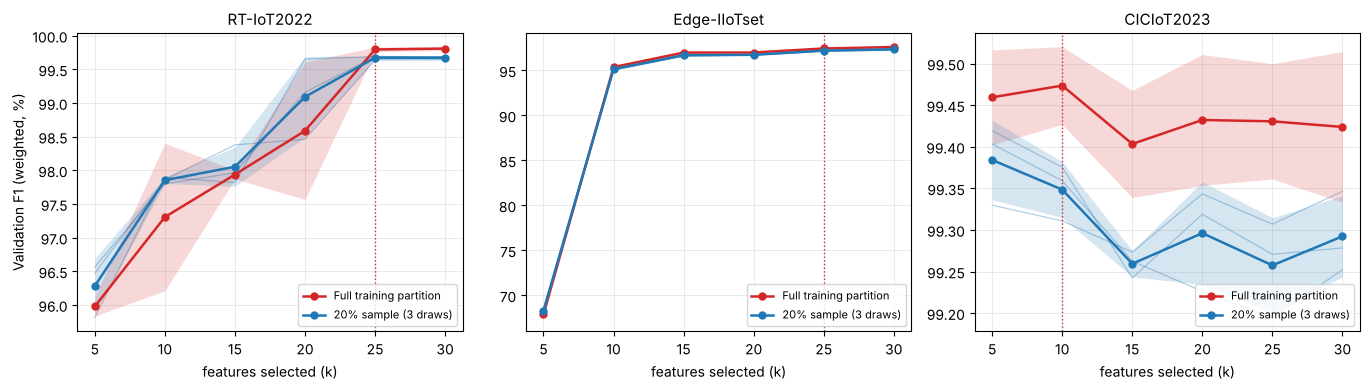

In [11]:
n = len(keys)
fig, axes = plt.subplots(1, n, figsize=(4.6 * n, 4.0), squeeze=False)
C_FULL, C_SAMP, C_TEST = "#d62728", "#1f77b4", "0.45"

for j, key in enumerate(keys):
    ax = axes[0][j]
    b = tab[tab.dataset == key].sort_values("k")
    ks = b.k.to_numpy()
    if len(per_draw):
        for ss, g in per_draw[per_draw.dataset == key].groupby("sample_seed"):
            g = g.sort_values("k")
            ax.plot(g.k, 100 * g.draw_mean, "-", color=C_SAMP, alpha=0.35, lw=0.9, zorder=1)
    series = [(b.full_mean, b.full_std, C_FULL, "Full training partition")]
    if b.samp_mean.notna().all():
        series.append((b.samp_mean, b.std_sampling, C_SAMP,
                       f"20% sample ({len(SAMPLE_SEEDS)} draws)"))
    for mu, sd, c, lab in series:
        mu, sd = 100 * mu.to_numpy(), 100 * np.nan_to_num(sd.to_numpy())
        ax.plot(ks, mu, "o-", color=c, lw=1.8, ms=5, label=lab, zorder=3)
        ax.fill_between(ks, mu - sd, mu + sd, color=c, alpha=0.18, lw=0, zorder=2)
    if SHOW_TEST_REFERENCE:
        ax.plot(ks, 100 * b.test_mean, "--", color=C_TEST, lw=1.2,
                label="Rev. 1 curve (test partition)", zorder=2)
    ax.axvline(kstar_full[key][0], color=C_FULL, ls=":", lw=1)
    ax.set_title(meta[key]["name"], fontsize=11)
    ax.set_xlabel("features selected (k)")
    if j == 0:
        ax.set_ylabel(f"Validation F1 ({F1_AVERAGE}, %)")
    ax.set_xticks(ks)
    ax.grid(alpha=0.3, lw=0.6)
    ax.legend(fontsize=8, loc="lower right")

fig.tight_layout()
os.makedirs(OUT_DIR, exist_ok=True)
for ext in ("png", "pdf"):
    p = os.path.join(OUT_DIR, f"sensitivity_sample_vs_full_val.{ext}")
    fig.savefig(p, dpi=300, bbox_inches="tight")
    print("wrote", p)
plt.show()

## 12. Save, with paste-ready rows for the two sensitivity tables

In [12]:
os.makedirs(OUT_DIR, exist_ok=True)
res.to_csv(os.path.join(OUT_DIR, "cgfs_budget_val_raw.csv"), index=False)
tab.to_csv(os.path.join(OUT_DIR, "cgfs_budget_val_summary.csv"), index=False)

NAMES = {"rt-iot": "RT-IoT2022  ", "edge-iiot": "Edge-IIoTset", "cic-iot": "CICIoT2023  "}

def row(key, mean_col, std_col, kbest, extra=""):
    b = tab[tab.dataset == key].sort_values("k")
    cells = []
    for _, r in b.iterrows():
        c = f"{100 * r[mean_col]:.2f} $\\pm$ {100 * r[std_col]:.2f}"
        cells.append(f"\\textbf{{{c}}}" if int(r.k) == kbest else c)
    return f"{NAMES[key]} & " + " & ".join(cells) + f" & {kbest}{extra} \\\\"

lines = ["% Table sensitivity_full (validation F1 on the full training partitions)"]
lines += [row(k, "full_mean", "full_std", kstar_full[k][0]) for k in keys]
if kstar_samp:
    lines += ["", "% Table sensitivity_sample (validation F1 on 20% samples of the training partitions)"]
    for k in keys:
        ks_ = kstar_samp[k][0]
        delta = 100 * (curves_samp[k][ks_] - curves_full[k][ks_])
        lines.append(row(k, "samp_mean", "std_sampling", ks_, f" & ${delta:+.2f}$"))
lines += ["", "% thresholds (full): " + ", ".join(f"{100 * kstar_full[k][1]:.3f}\\%" for k in keys)]
if kstar_samp:
    lines += ["% thresholds (sample): " + ", ".join(f"{100 * kstar_samp[k][1]:.3f}\\%" for k in keys)]
if iv:
    lines += [f"% tau interval with identical k*: {100 * iv[0]:.1f}\\% to {100 * iv[1]:.1f}\\%"]

p = os.path.join(OUT_DIR, "cgfs_budget_val_tables.tex")
open(p, "w").write("\n".join(lines) + "\n")
print("\n".join(lines))
print("\nwrote", p)

% Table sensitivity_full (validation F1 on the full training partitions)
RT-IoT2022   & 95.98 $\pm$ 0.14 & 97.31 $\pm$ 1.10 & 97.94 $\pm$ 0.06 & 98.59 $\pm$ 1.02 & \textbf{99.80 $\pm$ 0.04} & 99.81 $\pm$ 0.03 & 25 \\
Edge-IIoTset & 67.91 $\pm$ 0.38 & 95.37 $\pm$ 0.07 & 96.98 $\pm$ 0.01 & 96.99 $\pm$ 0.04 & \textbf{97.43 $\pm$ 0.05} & 97.60 $\pm$ 0.04 & 25 \\
CICIoT2023   & 99.46 $\pm$ 0.06 & \textbf{99.47 $\pm$ 0.05} & 99.40 $\pm$ 0.06 & 99.43 $\pm$ 0.08 & 99.43 $\pm$ 0.07 & 99.42 $\pm$ 0.09 & 10 \\

% Table sensitivity_sample (validation F1 on 20% samples of the training partitions)
RT-IoT2022   & 96.28 $\pm$ 0.41 & 97.85 $\pm$ 0.05 & 98.05 $\pm$ 0.29 & 99.09 $\pm$ 0.60 & \textbf{99.67 $\pm$ 0.03} & 99.67 $\pm$ 0.03 & 25 & $-0.12$ \\
Edge-IIoTset & 68.29 $\pm$ 0.30 & 95.14 $\pm$ 0.16 & 96.68 $\pm$ 0.11 & 96.73 $\pm$ 0.06 & \textbf{97.19 $\pm$ 0.07} & 97.34 $\pm$ 0.10 & 25 & $-0.24$ \\
CICIoT2023   & \textbf{99.38 $\pm$ 0.05} & 99.35 $\pm$ 0.03 & 99.26 $\pm$ 0.02 & 99.30 $\pm$ 0.06 & 9